# 01 · Download ERA5-Land monthly data

We download monthly means of **2 m temperature** (`t2m`, K) and **total precipitation** (`tp`, m/day)
from the Copernicus Climate Data Store (CDS) with `cdsapi`, for a box around the catchment and 1981–2020.

Before running: create a CDS account, accept the ERA5-Land licence and save your API key in `~/.cdsapirc`.
The download can wait in the CDS queue for a while; if the file already exists it is not downloaded again.

The monthly means of daily maximum and minimum temperature are provided in `data/raw/tmax_tmin.nc`.

In [1]:

import sys, json
from pathlib import Path
sys.path.insert(0, "../src")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

DATA = Path("../data")
PROC = DATA / "processed"
PROC.mkdir(exist_ok=True)
case = json.loads((DATA / "case.json").read_text())
case

{'catchment_area_km2': 55.33,
 'latitude_deg': 38.237,
 'longitude_deg': -7.687,
 'smax_mm': 100,
 'hmax_m': 5.0,
 'hmin_m': 1.0,
 'area_fixed_km2': 0.0685,
 'irrigation_months': [6, 7, 8, 9],
 'demand_hm3_per_month': 0.02,
 'eflow_fraction': 0.1,
 'target_reliability': 0.9}

The request: dataset `reanalysis-era5-land-monthly-means`, product `monthly_averaged_reanalysis`,
area `[N, W, S, E]` = catchment centre ± 1.5° (reaches the coast).

In [2]:
target = DATA / "raw" / "era5land_monthly.nc"
target.parent.mkdir(parents=True, exist_ok=True)   # create the folder

lat, lon = case["latitude_deg"], case["longitude_deg"]
area = [round(lat + 1.5, 1), round(lon - 1.5, 1),   # N, W, S, E
        round(lat - 1.5, 1), round(lon + 1.5, 1)]

if not target.exists():
    import cdsapi

    dataset = "reanalysis-era5-land-monthly-means"
    request = {
    "variable": ["2m_temperature", "total_precipitation"],
    "year": [str(y) for y in range(1981, 2021)],
    "month": [f"{m:02d}" for m in range(1, 13)],

    "time": [
        "00:00"
        ],
    "product_type": ["monthly_averaged_reanalysis"],
    "data_format": "netcdf",
    "download_format": "unarchived",

    "area": [44, -10, 36, 4]
    }

    client = cdsapi.Client()
    client.retrieve(dataset, request).download(target)

print(target, target.exists())

../data/raw/era5land_monthly.nc True


In [3]:
import xarray as xr
ds = xr.open_dataset(target)
ds

<xarray.Dataset> Size: 44MB
Dimensions:     (valid_time: 480, latitude: 81, longitude: 141)
Coordinates:
  * valid_time  (valid_time) datetime64[ns] 4kB 1981-01-01 ... 2020-12-01
    expver      (valid_time) <U4 8kB ...
  * latitude    (latitude) float64 648B 44.0 43.9 43.8 43.7 ... 36.2 36.1 36.0
  * longitude   (longitude) float64 1kB -10.0 -9.9 -9.8 -9.7 ... 3.7 3.8 3.9 4.0
    number      int64 8B ...
Data variables:
    t2m         (valid_time, latitude, longitude) float32 22MB ...
    tp          (valid_time, latitude, longitude) float32 22MB ...
Attributes:
    GRIB_centre:             ecmf
    GRIB_centreDescription:  European Centre for Medium-Range Weather Forecasts
    GRIB_subCentre:          0
    Conventions:             CF-1.7
    institution:             European Centre for Medium-Range Weather Forecasts
    history:                 2026-11-05T16:57 GRIB to CDM+CF via cfgrib-0.9.1...

Mean maps of the region with `meteoraster`: coastline, borders and the catchment (`catchment.kml`).
`to_meteoraster` wraps the NetCDF grid in a `MeteoRaster`; precipitation is converted to mm/year
(mean monthly total × 12).

/opt/anaconda3/envs/epss/lib/python3.12/site-packages/shapely/creation.py:746: RuntimeWarning: invalid value encountered in create_collection
  return lib.create_collection(geometries, np.intc(typ), out=out, **kwargs)


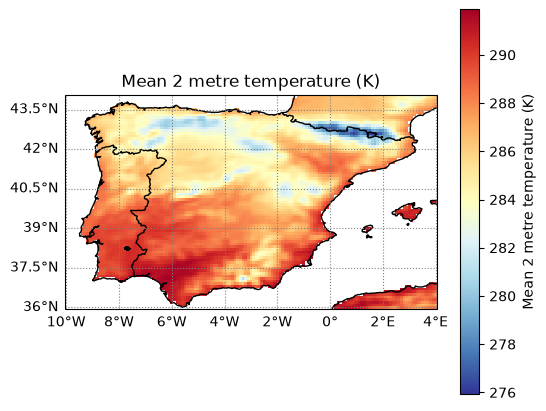

/opt/anaconda3/envs/epss/lib/python3.12/site-packages/shapely/creation.py:746: RuntimeWarning: invalid value encountered in create_collection
  return lib.create_collection(geometries, np.intc(typ), out=out, **kwargs)
/opt/anaconda3/envs/epss/lib/python3.12/site-packages/shapely/creation.py:746: RuntimeWarning: invalid value encountered in create_collection
  return lib.create_collection(geometries, np.intc(typ), out=out, **kwargs)


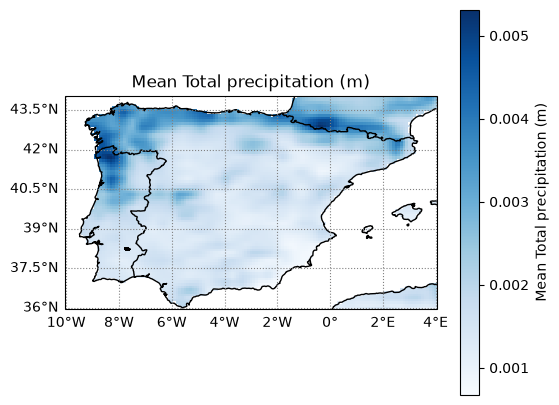

In [4]:
import cartopy.crs as ccrs
from epss.climate import to_meteoraster, catchment_polygon

catchment = catchment_polygon(DATA / "catchment.kml")
maps = []
for var, cmap in [("t2m", "RdYlBu_r"), ("tp", "Blues")]:
    da = ds[var]
    units = da.attrs.get("units", "")
    label = f"Mean {da.attrs.get('long_name', var)} ({units})"
    maps.append((to_meteoraster(da, var, units), label, cmap))
for mr, label, cmap in maps:
    ax = mr.create_plot(central_longitude=0, figsize=(6, 5))
    ax.add_geometries(catchment, crs=ccrs.PlateCarree(), facecolor="none", edgecolor="k", linewidth=1.5)
    ax.gridlines(draw_labels=["left", "bottom"], linestyle=":", color="grey")
    ax.set_title(label)                       # set before plot_mean, which calls plt.show()
    mr.plot_mean(ax=ax, coastline=True, borders=True, colorbar_label=label, cmap=cmap, add_labels=False)